Loaded: (367, 367, 3) (373, 373, 3)


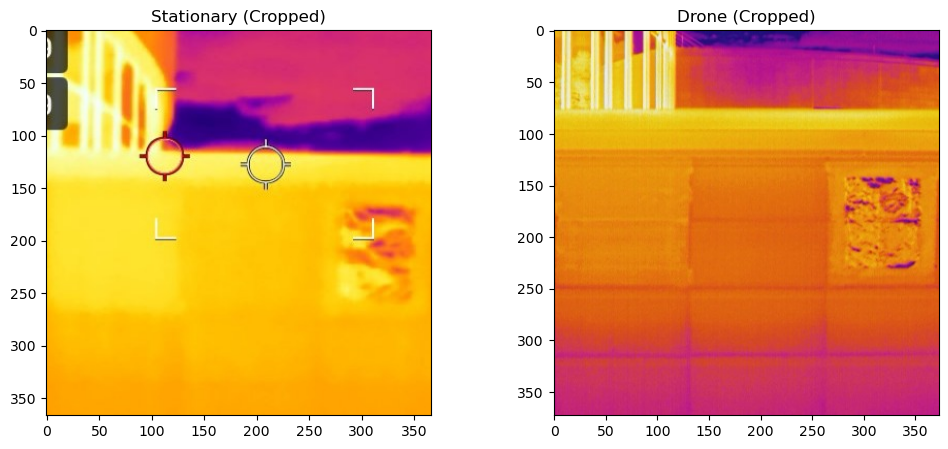

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import seaborn as sns

# ----------------------------
# UPDATE THESE PATHS
# ----------------------------
stat_path = r"C:\Users\murat\Downloads\STAT CROPPED NOV 17.JPG"
drone_path = r"C:\Users\murat\Downloads\DRONE CROPPED NOV 17.JPG"

# Load images (RGB for plotting, grayscale for pixel math)
stat_rgb = cv2.cvtColor(cv2.imread(stat_path), cv2.COLOR_BGR2RGB)
drone_rgb = cv2.cvtColor(cv2.imread(drone_path), cv2.COLOR_BGR2RGB)

stat_gray = cv2.cvtColor(stat_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
drone_gray = cv2.cvtColor(drone_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)

print("Loaded:", stat_rgb.shape, drone_rgb.shape)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(stat_rgb); plt.title("Stationary (Cropped)")
plt.subplot(1,2,2); plt.imshow(drone_rgb); plt.title("Drone (Cropped)")
plt.show()


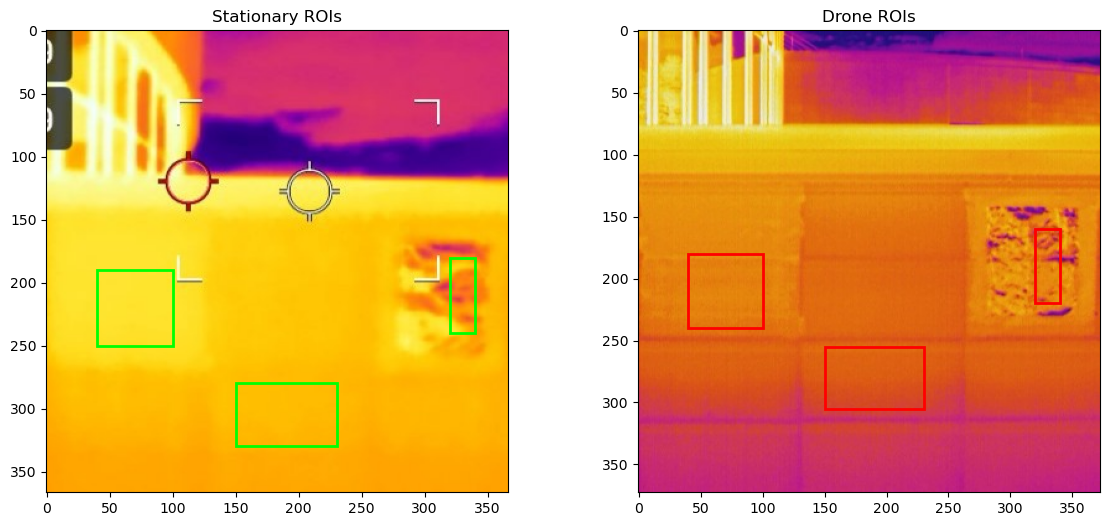

In [35]:
# =============================================
# MANUAL ROIs (x1, y1, x2, y2)
# ADJUST  BY LOOKING AT THE IMAGES
# =============================================

ROI_STAT = [
    (320, 180, 340, 240),   # Foil
    (40, 190, 100, 250),    # Black tape
    (150, 280, 230, 330)    # Background wall
]

ROI_DRONE = [
    (320, 160, 340, 220),   # Foil (match)
    (40, 180, 100, 240),    # Black tape (match)
    (150, 255, 230, 305)    # Background wall (match)
]

# Visualize
fig, ax = plt.subplots(1,2, figsize=(14,6))
ax[0].imshow(stat_rgb); ax[0].set_title("Stationary ROIs")
for (x1,y1,x2,y2) in ROI_STAT:
    ax[0].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   edgecolor='lime', linewidth=2, fill=False))

ax[1].imshow(drone_rgb); ax[1].set_title("Drone ROIs")
for (x1,y1,x2,y2) in ROI_DRONE:
    ax[1].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   edgecolor='red', linewidth=2, fill=False))
plt.show()


In [41]:
# Collect many pixel pairs from all ROIs
stat_pixels  = []
drone_pixels = []

for (s, d) in zip(ROI_STAT, ROI_DRONE):
    x1s, y1s, x2s, y2s = s
    x1d, y1d, x2d, y2d = d

    block_stat  = stat_gray[y1s:y2s, x1s:x2s].ravel()
    block_drone = drone_gray[y1d:y2d, x1d:x2d].ravel()

    # make sure lengths match (they should, if ROIs are same size)
    n = min(len(block_stat), len(block_drone))
    block_stat  = block_stat[:n]
    block_drone = block_drone[:n]

    stat_pixels.append(block_stat)
    drone_pixels.append(block_drone)

stat_pixels  = np.concatenate(stat_pixels)
drone_pixels = np.concatenate(drone_pixels)

print("Total paired pixels:", len(stat_pixels))

# Optional: subsample to, say, 5000 points for plotting speed
max_points = 5000
if len(stat_pixels) > max_points:
    idx = np.random.choice(len(stat_pixels), max_points, replace=False)
    stat_sample  = stat_pixels[idx]
    drone_sample = drone_pixels[idx]
else:
    stat_sample  = stat_pixels
    drone_sample = drone_pixels

print("Using", len(stat_sample), "points for regression.")


Total paired pixels: 8800
Using 5000 points for regression.


In [42]:
# X = drone, Y = stationary (we want to calibrate drone to match stationary)
X = drone_sample.reshape(-1, 1)
Y = stat_sample

lin = LinearRegression().fit(X, Y)
Y_pred = lin.predict(X)
r2 = r2_score(Y, Y_pred)

a = float(lin.coef_[0])
b = float(lin.intercept_)

print(f"Linear model:  Stationary ≈ {a:.4f} * Drone + {b:.4f}")
print(f"R² = {r2:.3f}")


Linear model:  Stationary ≈ 0.6666 * Drone + 105.6836
R² = 0.228


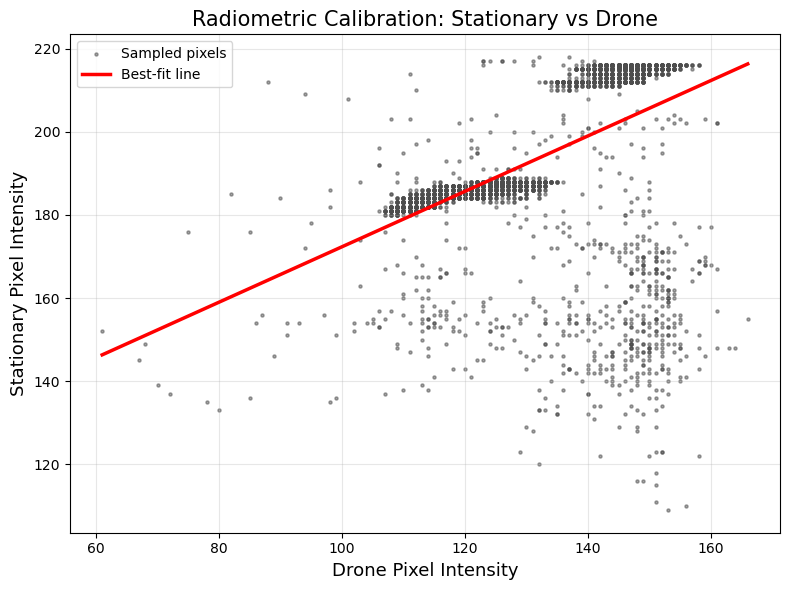

In [43]:
plt.figure(figsize=(8,6))

plt.scatter(drone_sample, stat_sample, s=5, c='0.3', alpha=0.5, label="Sampled pixels")

x_line = np.linspace(drone_sample.min(), drone_sample.max(), 200).reshape(-1,1)
y_line = lin.predict(x_line)

plt.plot(x_line, y_line, color='red', linewidth=2.5, label="Best-fit line")

plt.xlabel("Drone Pixel Intensity", fontsize=13)
plt.ylabel("Stationary Pixel Intensity", fontsize=13)
plt.title("Radiometric Calibration: Stationary vs Drone", fontsize=15)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


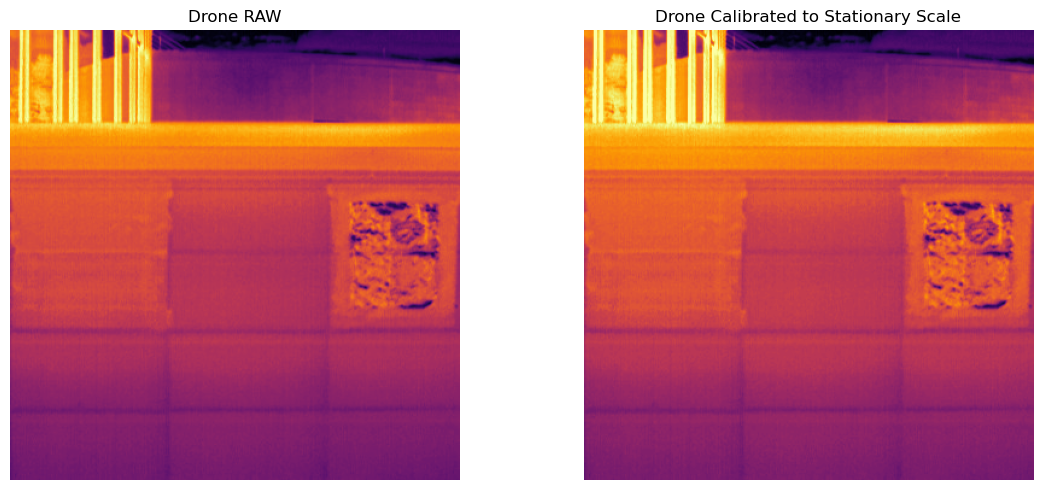

In [44]:
# Apply: Stationary ≈ a * Drone + b  → calibrated version of drone
drone_calibrated = a * drone_gray + b

# Clip to valid range
drone_calibrated_disp = np.clip(drone_calibrated, 0, 255).astype(np.uint8)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(drone_gray, cmap='inferno')
plt.title("Drone RAW")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(drone_calibrated_disp, cmap='inferno')
plt.title("Drone Calibrated to Stationary Scale")
plt.axis('off')

plt.tight_layout()
plt.show()
